# Phase 2: Nominal edges vs. hour baseline

**Question:** Given hour, weather, and the four sensors, how well can we recover the true level of each gas when every sensor is tied only to the gas it is designed for?

1. **Per gas:** how much do sensors + weather add over `HourOnlyBaseline`?
2. **Overconfidence:** Phase 1b (all sensors, CO only) was more accurate but worse calibrated. Dropping any sensor raised log-likelihood, because the sensors were treated as independent witnesses of CO. With each sensor tied to its own gas, does that go away? Rerun the drop-one-sensor ablation.
3. **EM:** each gas reference is missing on ~18% of hours. How much does EM gain over complete-case counting?

**Where this sits.** Each phase adds one thing, and everything else is held identical:
- **Phase 2 (this notebook):** nominal edges only.
- **Phase 3a:** Phase 2 + the cross-sensitivity edges from the study (#16). So 2 → 3a measures what the cross edges buy.
- **Phase 3b:** 3a + a latent traffic node. So 3a → 3b measures the latent node.

To keep 2 → 3a a clean comparison, this notebook uses 3a's gases, sensors, weather, splits, seeds, bin counts and model settings; only the sensor edges differ.

**Network** (Figure 2):

```
hour ──► CO, NOx, NO2
gas  ──► its nominal sensor             S1 ← CO,  S3 ← NOx,  S4 ← NO2
S5   (no gas parent: it targets O3, which has no reference)
W = (T, RH) ──► every sensor
```

**Assumptions:**
- **A1.** Each gas depends on hour only. The gases are independent given hour; their co-movement beyond the hour is not modelled.
- **A2.** Each sensor depends only on its gas parent and weather. Given those, the sensors are independent of each other.
- **A3.** Missingness is ignorable given the observed values (MAR).
- **A4.** Hours are independent given the CPTs (no temporal dependence; that's future work).

**Rules:** 
- Every choice (bin count) is made on **val**. **Test** is scored once, at the end, for the chosen configuration. Every metric for a (model, gas, evidence) comes from **one** `predict_proba` call.

**Sections**
1. Setup
2. Data and variables
3. Network
4. Splits
5. Metrics
6. Grid: bins × seed (6 runs)
7. Results per gas, and the chosen bin count
8. Calibration
9. Follow-ups: drop-one-sensor ablation, EM vs complete-case
10. Assumptions A1–A4
11. Drift check (time-based split)
12. Test set (chosen configuration, once)

The standard concentration evaluation is added separately (shared helpers in `src/cse250a/modules/eval/`). Section 6 keeps what it needs: a long-format concentration table and the per-split estimates.

**Outputs:** tables in `results/phase2/` (the grid is `results/phase2/grid.csv`, the hand-off table `results/phase2/concentration_grid.csv`), images in `figures/phase2/`.

## 1. Setup

In [ ]:
%load_ext autoreload
%autoreload 2

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from cse250a.modules.config import config
from cse250a.modules.core import TIME_CARDS, Gas, Network, Sensor, Time, Weather
from cse250a.modules.data import Discretizer, blocked_split, load_air_quality
from cse250a.modules.eval import (
    bin_means,
    concentration_error,
    expected_concentration,
    partial_spearman,
    resolution_floor,
    score,
)
from cse250a.modules.models import HourOnlyBaseline, LayeredBN

## 2. Data and variables

- **Gases:** CO, NOx, NO2. C6H6 is out because it behaves like a transform of S2, and NMHC is out because it is too sparse to score meaningfully.
- **Weather `W` = T + RH**.
- **Sensors:** S1, S3, S4, S5. S2 is out with NMHC and C6H6.
- **Evidence** for every query: hour, weather and the four sensors.

Rows with a missing hour or weather are dropped, because those are inputs with no CPT, so they must be observed on every row. The sensors are missing on exactly those rows too, so after this every sensor is always observed and only the gas references have holes.

In [ ]:
df = load_air_quality(config.paths.air_quality_csv)
print(df.shape)
df.isna().mean().round(3).rename("fraction missing").to_frame().T

(9357, 17)


,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,hour,dow,is_weekday,season
fraction missing,0.18,0.039,0.902,0.039,0.039,0.175,0.039,0.175,0.039,0.039,0.039,0.039,0.039,0.0,0.0,0.0,0.0


In [ ]:
gases = (Gas.CO, Gas.NOX, Gas.NO2)
weather = (Weather.T, Weather.RH)
sensors = (Sensor.S1, Sensor.S3, Sensor.S4, Sensor.S5)

before = len(df)
df = df.dropna(subset=[Time.HOUR, *weather])
print(f"dropped {before - len(df)} rows with missing weather; {len(df)} left")

dropped 366 rows with missing weather; 8991 left


**Two things to watch in the results:**
- **S5 has no gas parent in Phase 2, so it does not affect the gas posteriors.** It is still evidence, but with only T and RH as parents it carries no information about any gas: dropping it changes nothing (section 9.1). That is expected. Its contribution only shows up in 3a, through the cross-sensitivity edges (S5 ← CO, NOx).
- **CO vs Phase 1.** In Phase 1b every sensor was a child of CO; here only S1 is. Phase 2's CO uses less sensor evidence, so its point estimate may not improve on Phase 1's, but it should be better calibrated. Called out where it happens.

## 3. Network

Each sensor gets only the gas it is designed for: S1 ← CO, S3 ← NOx, S4 ← NO2. S5 is nominally an O3 sensor and there is no O3 reference, so it has weather parents only. Every sensor also has T and RH as parents, and every gas has the hour.

In [ ]:
nominal = {
    Sensor.S1: (Gas.CO,),
    Sensor.S3: (Gas.NOX,),
    Sensor.S4: (Gas.NO2,),
}


def structure(edges=nominal, weather=weather):
    """hour → every gas; each sensor ← its gas parents + weather."""
    return {
        **{g: (Time.HOUR,) for g in gases},
        **{s: (*edges.get(s, ()), *weather) for s in sensors},
    }


def phase1b_structure(weather=weather, target=Gas.CO):
    """Phase 1b's network (example.ipynb): one gas, every sensor its child."""
    return {
        target: (Time.HOUR,),
        **{s: (target, *weather) for s in sensors},
    }

## 4. Splits

`blocked_split` shuffles whole **weeks** into train / val / test (50 / 25 / 25), so neighbouring hours don't land on both sides. Bin edges are learned on **train only**, then applied to every part. Each split also keeps each gas's **bin means** c̄ₖ (the mean raw concentration of the training hours in bin k), which turn a posterior back into a concentration:

$$\widehat{c}_t = \sum_k P(\text{bin}_k \mid \text{evidence}_t)\,\bar c_k$$

Bin counts 3 and 5, seeds 0–2, as in Phase 3a. Splits are keyed by `(bins, seed)`; the bin count changes only the discretizer, not which hours are in each part.

`time_split` (section 11) is the chronological alternative: train on the earliest half, val and test on later months.

In [ ]:
ALPHA = config.bins.alpha  # Laplace pseudo-count, the same as Phase 1 and 3a
BIN_COUNTS = (config.bins.n_bins, 5)  # 3 and 5, as in Phase 3a
SEEDS = (0, 1, 2)

train_raw, val_raw, test_raw = blocked_split(df, seed=config.seed)
print(
    {
        name: len(d)
        for name, d in [("train", train_raw), ("val", val_raw), ("test", test_raw)]
    }
)

{'train': 4500, 'val': 2259, 'test': 2232}


In [ ]:
binned = [*gases, *sensors, *weather]
disc = Discretizer(n_bins=BIN_COUNTS[0]).fit(train_raw, binned)
train, val, test = (disc.transform(d) for d in (train_raw, val_raw, test_raw))

cards = {**disc.cards, **TIME_CARDS}
print("cards:", {str(k): v for k, v in cards.items() if k in binned or k == Time.HOUR})
train[binned].head()

cards: {'CO(GT)': 3, 'NOx(GT)': 3, 'NO2(GT)': 3, 'PT08.S1(CO)': 3, 'PT08.S3(NOx)': 3, 'PT08.S4(NO2)': 3, 'PT08.S5(O3)': 3, 'T': 3, 'RH': 3, 'hour': 24}


,CO(GT),NOx(GT),NO2(GT),PT08.S1(CO),PT08.S3(NOx),PT08.S4(NO2),PT08.S5(O3),T,RH
datetime,,,,,,,,,
2004-03-17 18:00:00,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,0.0
2004-03-17 19:00:00,2.0,2.0,2.0,2.0,0.0,2.0,2.0,1.0,0.0
2004-03-17 20:00:00,2.0,2.0,2.0,2.0,0.0,2.0,2.0,1.0,1.0
2004-03-17 21:00:00,2.0,2.0,2.0,2.0,0.0,2.0,2.0,1.0,1.0
2004-03-17 22:00:00,2.0,1.0,2.0,2.0,1.0,2.0,2.0,1.0,1.0


In [ ]:
def time_split(df, train=0.5, val=0.25, seed=None):
    """Chronological 50 / 25 / 25: train on the earliest hours, test on the latest.
    `seed` is unused; it keeps the signature of blocked_split."""
    a, b = round(len(df) * train), round(len(df) * (train + val))
    return df.iloc[:a], df.iloc[a:b], df.iloc[b:]


def make_split(seed, n_bins, *, split=blocked_split):
    """The two cells above for any bin count and seed, plus each gas's bin means c̄ₖ (from train)."""
    train_raw, val_raw, test_raw = split(df, seed=seed)
    disc = Discretizer(n_bins=n_bins).fit(train_raw, binned)
    train, val, test = (disc.transform(d) for d in (train_raw, val_raw, test_raw))
    cards = {**disc.cards, **TIME_CARDS}
    c_bar = {g: bin_means(train_raw[g], train[g]) for g in gases}  # index: bin → mean
    return {
        "bins": n_bins,
        "seed": seed,
        "discretizer": disc,
        "train_raw": train_raw,
        "val_raw": val_raw,
        "test_raw": test_raw,
        "train": train,
        "val": val,
        "test": test,
        "cards": cards,
        "c_bar": c_bar,
    }


splits = {(b, seed): make_split(seed, b) for b in BIN_COUNTS for seed in SEEDS}
pd.DataFrame(
    {
        f"seed {seed}": {
            **{f"{k} hours": len(sp[f"{k}_raw"]) for k in ("train", "val", "test")},
            **{
                f"{k} {g} hours": int(sp[f"{k}_raw"][g].notna().sum())
                for k in ("val", "test")
                for g in gases
            },
        }
        for (b, seed), sp in splits.items()
        if b == BIN_COUNTS[0]
    }
)

,seed 0,seed 1,seed 2
train hours,4500,4573,4485
val hours,2259,2146,2164
test hours,2232,2272,2342
val CO(GT) hours,2064,1697,1798
val NOx(GT) hours,1942,1746,1877
val NO2(GT) hours,1942,1746,1876
test CO(GT) hours,1643,1848,1762
test NOx(GT) hours,1657,1865,1806
test NO2(GT) hours,1656,1864,1805


In [ ]:
network = Network(
    structure=structure(),
    cards=cards,
).validate(train.columns)
print(network)

Network(7 nodes, inputs: hour, T, RH)
          CO(GT) | hour                          CPT shape (24, 3)
         NOx(GT) | hour                          CPT shape (24, 3)
         NO2(GT) | hour                          CPT shape (24, 3)
     PT08.S1(CO) | CO(GT), T, RH                 CPT shape (3, 3, 3, 3)
    PT08.S3(NOx) | NOx(GT), T, RH                CPT shape (3, 3, 3, 3)
    PT08.S4(NO2) | NO2(GT), T, RH                CPT shape (3, 3, 3, 3)
     PT08.S5(O3) | T, RH                         CPT shape (3, 3, 3)


## 5. Metrics

Per gas, on the hours where that gas's reference is observed (`n`):
- **MAE / RMSE**: of the concentration estimate Σₖ P(binₖ) c̄ₖ, in the gas's units. **The headline metric.**
- **floor_MAE / floor_RMSE**: the **resolution floor**, the error of a *perfect* bin prediction that puts every hour at its true bin's c̄ₖ. It's the practical limit of these bins; a soft posterior can land slightly below it, because averaging bin means sometimes beats the hard bin mean
- **mean_log_likelihood**: mean log P(true bin). Higher (closer to 0) is better. Used for the overconfidence story (ablation)
- **ECE**: expected calibration error. Hours are grouped by confidence (the top probability); ECE is the hour-weighted mean of |hit rate − confidence|. 0 is perfectly calibrated

Each is compared with `HourOnlyBaseline`, which gets the same split, bins and evidence. Concentration errors are in real units, so they can be compared across bin counts directly; log-likelihood can't (more bins are harder to hit), so it is compared by **gain over the baseline**.

In [ ]:
evidence = (Time.HOUR, *weather, *sensors)
metrics = ["n", "mean_log_likelihood", "ECE", "MAE", "RMSE", "floor_MAE", "floor_RMSE"]
model_names = {"layered_bn": "BN", "hour_baseline": "HourOnlyBaseline"}
units = {"CO": "mg/m³", "NOx": "ppb", "NO2": "µg/m³"}
FIG = "phase2"  # images go to figures/phase2/, tables to results/phase2/


def short(name):
    """'PT08.S4(NO2)' -> 'S4', 'NOx(GT)' -> 'NOx'."""
    if name.startswith("PT08."):
        return name[5:7]
    return name.split("(")[0]


def reliability(proba, truth, bins=10):
    """Confidence vs hit rate, grouped by confidence. Returns (table, ECE)."""
    seen = truth.notna()
    conf = proba[seen].max(axis=1)
    hit = (proba[seen].idxmax(axis=1) == truth[seen]).astype(float)
    bucket = np.minimum((conf * bins).astype(int), bins - 1)
    t = (
        pd.DataFrame({"confidence": conf, "hit_rate": hit})
        .groupby(bucket)
        .agg(
            confidence=("confidence", "mean"),
            hit_rate=("hit_rate", "mean"),
            n=("hit_rate", "size"),
        )
    )
    ece = float((t.n / t.n.sum() * (t.hit_rate - t.confidence).abs()).sum())
    return t, ece


def gas_metrics(proba, split, gas, part="val"):
    """Every metric for one gas from one predict_proba output, on the hours with a
    reference. Concentrations use the shared helpers in cse250a.modules.eval."""
    truth = split[part][gas]
    raw = split[f"{part}_raw"][gas]
    c_bar = split["c_bar"][gas]
    seen = truth.notna()
    err = concentration_error(expected_concentration(proba, c_bar), raw)
    floor = resolution_floor(raw, truth, c_bar)
    return {
        "n": err["n"],
        "mean_log_likelihood": score(truth[seen], proba[seen])["mean_log_likelihood"],
        "ECE": reliability(proba, truth)[1],
        "MAE": err["MAE"],
        "RMSE": err["RMSE"],
        "floor_MAE": floor["MAE"],
        "floor_RMSE": floor["RMSE"],
    }


def evaluate_all(model, split, part="val", gases=gases, evidence=evidence):
    """predict_proba once per gas. Returns ({gas: proba}, [one metrics row per gas])."""
    probas, rows = {}, []
    for gas in gases:
        probas[gas] = model.predict_proba(split[part], gas, evidence)
        rows.append(
            {
                "gas": short(gas),
                "model": model_names.get(model.name, model.name),
                **gas_metrics(probas[gas], split, gas, part),
            }
        )
    return probas, rows


def fit_bn(split, struct, **kwargs):
    network = Network(
        structure=struct,
        cards=split["cards"],
    ).validate(split["train"].columns)
    return LayeredBN(network, alpha=ALPHA, seed=split["seed"], **kwargs).fit(
        split["train"]
    )


def fit_hour(split):
    return HourOnlyBaseline(cards=split["cards"], alpha=ALPHA).fit(split["train"])


def mean_std(frame, by, cols, digits=3):
    """'mean ± std' over seeds, with n as its mean."""
    g = frame.groupby(by, sort=False)
    out = (
        g[cols].mean().round(digits).astype(str)
        + " ± "
        + g[cols].std().fillna(0).round(digits).astype(str)
    )
    if "n" in frame:
        out.insert(0, "n", g["n"].mean().round().astype(int))
    return out

## 6. Grid: bins × seed

bins ∈ {3, 5} × seed ∈ {0, 1, 2} → 6 runs, the same grid as Phase 3a. Each run fits **one** BN (EM, `max_iter=100`) and answers every gas from it, and fits `HourOnlyBaseline` on the same split and bins. Every `predict_proba` is kept in `posteriors`, so later sections reuse it instead of predicting again.

For the shared concentration evaluation, each split also keeps the val concentration estimates (`splits[(bins, seed)]["estimates"]`, one column per gas for `BN` and `HourOnlyBaseline`) next to `val_raw`, `c_bar` and the `discretizer`, and `results/phase2/concentration_grid.csv` has one row per (bins, seed, gas, model) with `n`, `MAE` and `RMSE`, where model is `BN`, `HourOnlyBaseline` or `resolution_floor`.

In [ ]:
rows, fits, posteriors = [], {}, {}
for (b, seed), sp in splits.items():
    t0 = time.perf_counter()
    bn = fit_bn(sp, structure())
    hour = fit_hour(sp)
    fits[(b, seed)] = bn

    sp["estimates"] = {}
    for model in (bn, hour):
        name = model_names[model.name]
        posteriors[(b, seed, name)], gas_rows = evaluate_all(model, sp)
        sp["estimates"][name] = pd.DataFrame(
            {
                short(g): expected_concentration(p, sp["c_bar"][g])
                for g, p in posteriors[(b, seed, name)].items()
            }
        )
        rows += [{"bins": b, "seed": seed, **g} for g in gas_rows]
    r = bn.result
    print(
        f"bins={b} seed={seed}: {r.n_iter} iterations, converged: {r.converged}, "
        f"monotone: {r.is_monotone()}, {time.perf_counter() - t0:.0f}s",
        flush=True,
    )

grid = pd.DataFrame(rows)
grid.to_csv(config.paths.result(FIG, "grid.csv"), index=False)

# hand-off for the shared concentration evaluation: one row per (bins, seed, gas, model)
floor_rows = grid[grid.model == "BN"].assign(
    model="resolution_floor", MAE=lambda d: d.floor_MAE, RMSE=lambda d: d.floor_RMSE
)
concentration_grid = pd.concat([grid, floor_rows])[
    ["bins", "seed", "gas", "model", "n", "MAE", "RMSE"]
]
concentration_grid["gas"] = concentration_grid["gas"].map(
    {short(g): str(g) for g in gases}
)  # 'CO(GT)', as in Phase 1 / 3a
concentration_grid = concentration_grid.sort_values(
    ["bins", "seed", "gas", "model"]
).reset_index(drop=True)
concentration_grid.to_csv(
    config.paths.result(FIG, "concentration_grid.csv"), index=False
)
grid.head()

bins=3 seed=0: 6 iterations, converged: True, monotone: True, 1s


bins=3 seed=1: 5 iterations, converged: True, monotone: True, 1s


bins=3 seed=2: 7 iterations, converged: True, monotone: True, 1s


bins=5 seed=0: 8 iterations, converged: True, monotone: True, 6s


bins=5 seed=1: 6 iterations, converged: True, monotone: True, 4s


bins=5 seed=2: 7 iterations, converged: True, monotone: True, 5s


,bins,seed,gas,model,n,mean_log_likelihood,ECE,MAE,RMSE,floor_MAE,floor_RMSE
0,3,0,CO,BN,2064,-0.578405,0.016196,0.616284,0.921153,0.525843,0.811676
1,3,0,NOx,BN,1942,-0.654885,0.044081,93.793017,139.171416,91.810087,135.313461
2,3,0,NO2,BN,1942,-0.966292,0.088531,30.765547,41.141771,17.365146,24.381406
3,3,0,CO,HourOnlyBaseline,2064,-0.854285,0.033818,0.826887,1.172437,0.525843,0.811676
4,3,0,NOx,HourOnlyBaseline,1942,-0.996650,0.099324,134.073943,193.176747,91.810087,135.313461


## 7. Results

### 7.1 Per gas: Phase 2 vs `HourOnlyBaseline`

`MAE_hour` is the baseline's concentration error and `floor_MAE` the resolution floor, both in the gas's units. `rel_MAE` = MAE / MAE_hour (below 1 beats the hour alone). `gain_mean_log_likelihood` = BN − baseline on the same run. Mean ± std over seeds 0–2.

In [ ]:
keys = ["bins", "seed", "gas"]
bn_rows = grid[grid.model == "BN"].set_index(keys)
hour_rows = grid[grid.model == "HourOnlyBaseline"].set_index(keys)

gains = bn_rows.copy()
gains["MAE_hour"] = hour_rows["MAE"]
gains["RMSE_hour"] = hour_rows["RMSE"]
gains["rel_MAE"] = bn_rows["MAE"] / hour_rows["MAE"]  # < 1: better than the hour alone
gains["gain_mean_log_likelihood"] = (
    bn_rows["mean_log_likelihood"] - hour_rows["mean_log_likelihood"]
)
gains["ECE_hour"] = hour_rows["ECE"]
gains = gains.reset_index()

per_gas = mean_std(
    gains,
    ["gas", "bins"],
    [
        "MAE",
        "MAE_hour",
        "floor_MAE",
        "rel_MAE",
        "RMSE",
        "RMSE_hour",
        "floor_RMSE",
        "mean_log_likelihood",
        "gain_mean_log_likelihood",
        "ECE",
        "ECE_hour",
    ],
)
per_gas.to_csv(config.paths.result(FIG, "per_gas.csv"))
per_gas

,,n,MAE,MAE_hour,floor_MAE,rel_MAE,RMSE,RMSE_hour,floor_RMSE,mean_log_likelihood,gain_mean_log_likelihood,ECE,ECE_hour
gas,bins,,,,,,,,,,,,
CO,3,1853,0.598 ± 0.033,0.857 ± 0.039,0.461 ± 0.058,0.699 ± 0.042,0.868 ± 0.051,1.151 ± 0.036,0.706 ± 0.094,-0.606 ± 0.034,0.293 ± 0.016,0.028 ± 0.012,0.047 ± 0.012
NOx,3,1855,97.872 ± 3.967,136.469 ± 5.586,74.131 ± 18.198,0.718 ± 0.044,140.423 ± 10.534,186.456 ± 19.586,116.965 ± 26.796,-0.704 ± 0.048,0.296 ± 0.04,0.036 ± 0.011,0.061 ± 0.037
NO2,3,1855,32.182 ± 2.615,31.977 ± 2.802,16.981 ± 1.757,1.007 ± 0.02,41.458 ± 4.261,41.443 ± 3.989,23.135 ± 3.518,-0.986 ± 0.018,-0.021 ± 0.009,0.086 ± 0.028,0.073 ± 0.015
CO,5,1853,0.543 ± 0.037,0.845 ± 0.039,0.32 ± 0.051,0.643 ± 0.031,0.775 ± 0.049,1.142 ± 0.033,0.54 ± 0.086,-0.994 ± 0.044,0.38 ± 0.031,0.035 ± 0.006,0.038 ± 0.007
NOx,5,1855,87.343 ± 4.703,135.97 ± 5.211,50.439 ± 15.14,0.643 ± 0.037,125.626 ± 11.404,185.692 ± 18.942,87.98 ± 25.115,-1.046 ± 0.052,0.454 ± 0.057,0.038 ± 0.015,0.045 ± 0.035
NO2,5,1855,30.809 ± 2.626,31.838 ± 2.696,11.349 ± 0.958,0.968 ± 0.022,40.038 ± 4.335,41.279 ± 3.949,16.825 ± 2.822,-1.448 ± 0.027,0.009 ± 0.015,0.076 ± 0.004,0.045 ± 0.012


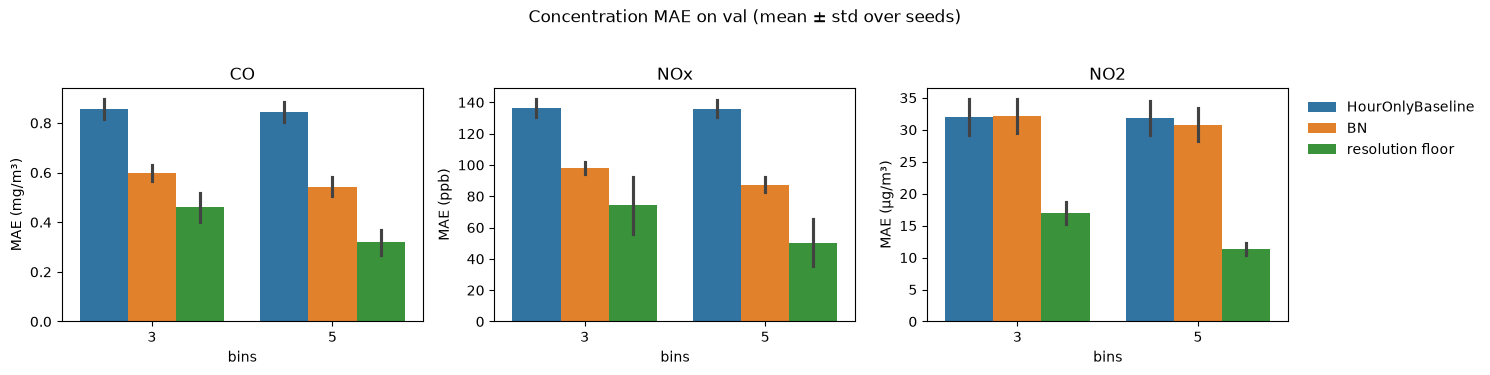

In [ ]:
order = ["HourOnlyBaseline", "BN", "resolution floor"]
long = pd.concat(
    [
        gains.assign(label="BN")[["gas", "bins", "seed", "label", "MAE"]],
        gains.assign(label="HourOnlyBaseline", MAE=gains.MAE_hour)[
            ["gas", "bins", "seed", "label", "MAE"]
        ],
        gains.assign(label="resolution floor", MAE=gains.floor_MAE)[
            ["gas", "bins", "seed", "label", "MAE"]
        ],
    ]
)

fig, axes = plt.subplots(1, len(gases), figsize=(15, 3.6))
for ax, gas in zip(axes, map(short, gases), strict=True):
    sns.barplot(
        data=long[long.gas == gas],
        x="bins",
        y="MAE",
        hue="label",
        hue_order=order,
        errorbar="sd",
        ax=ax,
        legend=ax is axes[-1],
    )
    ax.set_title(gas)
    ax.set_ylabel(f"MAE ({units[gas]})")
axes[-1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
fig.suptitle("Concentration MAE on val (mean ± std over seeds)", y=1.03)
plt.tight_layout()
plt.savefig(config.paths.figure(FIG, "mae_vs_floor.png"), bbox_inches="tight")
plt.show()

**Reading:** (val, mean ± std over seeds; n ≈ 1855 val hours per gas, 1853 for CO)
- **CO and NOx clearly beat the hour baseline, at both bin counts.** At 5 bins, CO MAE is 0.543 ± 0.037 vs 0.845 mg/m³ (floor 0.320) and log-lik gain +0.380 ± 0.031; NOx MAE is 87.3 ± 4.7 vs 136.0 ppb (floor 50.4) and log-lik gain +0.454 ± 0.057.
- **NO2 does not really beat it.** At 5 bins its MAE is 30.8 ± 2.6 vs 31.8 µg/m³ (log-lik gain +0.009 ± 0.015, within noise), and at 3 bins it is slightly *worse* than the baseline (32.2 vs 32.0, log-lik −0.021 ± 0.009). Its only witness, S4, carries little NO2 information (see 9.1), and its MAE stays far above the floor (31 vs 11).
- **5 bins beat 3 bins for every gas** in concentration error, and the gap to the floor shrinks for CO and NOx; with nominal edges each sensor CPT has only 3 parents, so 5 bins stay well estimated.
- **CO vs Phase 1** (Phase 1 rerun on the same sensors, weather, splits and bins; mean over seeds 0–2): Phase 2's CO MAE is 0.598 ± 0.033 vs 0.544 ± 0.031 at 3 bins, and 0.543 ± 0.037 vs 0.475 ± 0.033 at 5 bins; mean log-lik is better at 3 bins (−0.606 vs −0.661). With nominal edges, S1 is CO's only sensor (S3 and S4 belong to other gases, which are independent of CO given the hour), so the point estimate is worse than Phase 1's, which uses all four sensors as CO witnesses. In exchange it is no longer overconfident: at 5 bins CO's ECE is 0.035 vs 0.161 for the Phase 1 network (9.1). Getting the other sensors' CO information back without double-counting is what the cross edges in 3a are for.

### 7.2 Chosen bin count

**Selection criterion:** concentration MAE relative to the hour baseline (`rel_MAE` = MAE / MAE_hour, so gases in different units can be averaged), averaged over CO, NOx and NO2 and over seeds, on **val**. Lower is better. The follow-ups below use the chosen bin count.

In [ ]:
selection = (
    gains.groupby(["bins", "seed"])["rel_MAE"]
    .mean()  # one number per run
    .groupby("bins")
    .agg(["mean", "std"])
    .sort_values("mean")
)
chosen = int(selection["mean"].idxmin())
print(f"chosen: bins={chosen}")
selection.round(4)

chosen: bins=5


,mean,std
bins,,
5,0.7512,0.0058
3,0.8079,0.0166


**Reading:** **5 bins is chosen**: relative MAE 0.751 ± 0.006 vs 0.808 ± 0.017 at 3 bins, lower for all three gases on every seed. Everything below uses 5 bins.

## 8. Calibration: confidence vs hit rate

For the chosen bin count, pooled over seeds. Each point is a group of val hours with similar confidence (the model's top probability); on the diagonal, a model that says 80% is right 80% of the time. Below the diagonal is **overconfident**.

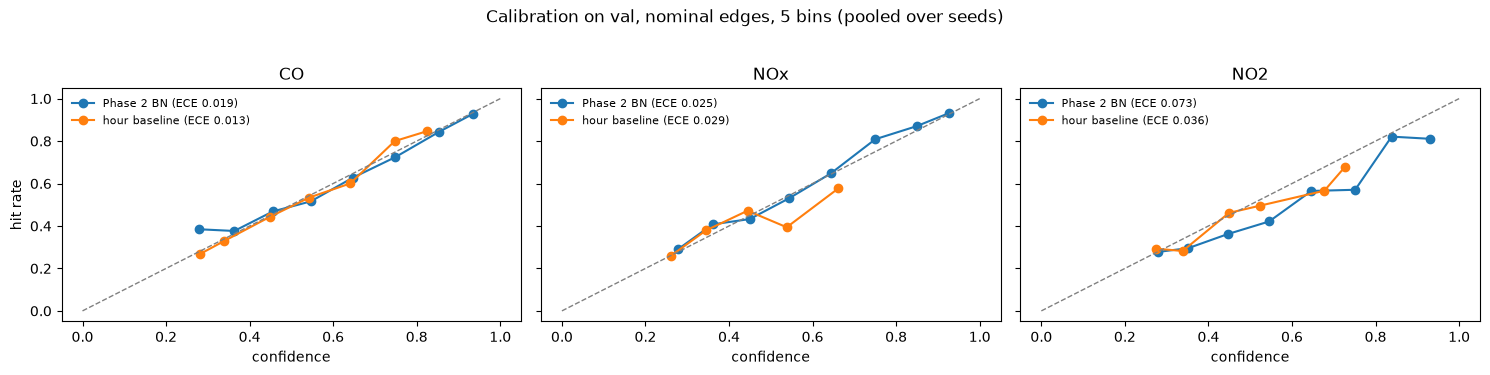

In [ ]:
def pooled(model_name, gas, bins=chosen):
    """(proba, truth) for one gas, concatenated over seeds."""
    probas = [posteriors[(bins, s, model_name)][gas] for s in SEEDS]
    truths = [splits[(bins, s)]["val"][gas] for s in SEEDS]
    return pd.concat(probas, ignore_index=True), pd.concat(truths, ignore_index=True)


fig, axes = plt.subplots(1, len(gases), figsize=(15, 3.6), sharey=True)
for ax, gas in zip(axes, gases, strict=True):
    for model_name, label in [
        ("BN", "Phase 2 BN"),
        ("HourOnlyBaseline", "hour baseline"),
    ]:
        t, ece = reliability(*pooled(model_name, gas))
        ax.plot(t.confidence, t.hit_rate, marker="o", label=f"{label} (ECE {ece:.3f})")
    ax.plot([0, 1], [0, 1], ls="--", c="gray", lw=1)
    ax.set_title(short(gas))
    ax.set_xlabel("confidence")
    ax.legend(fontsize=8, frameon=False)
axes[0].set_ylabel("hit rate")
fig.suptitle(
    f"Calibration on val, nominal edges, {chosen} bins (pooled over seeds)", y=1.03
)
plt.tight_layout()
plt.savefig(config.paths.figure(FIG, "calibration.png"), bbox_inches="tight")
plt.show()

**Reading:** **CO and NOx are well calibrated, and better than the baseline:** ECE 0.035 ± 0.006 vs 0.038 (CO) and 0.038 ± 0.015 vs 0.045 (NOx), with the curves close to the diagonal. **NO2 is the exception:** ECE 0.076 ± 0.004 vs 0.045 for the baseline, overconfident at higher confidence. S4's weak, noisy link to NO2 sharpens the posterior without making it more right.

## 9. Follow-ups at the chosen configuration

### 9.1 Drop-one-sensor ablation

In Phase 1b, every sensor was a child of CO only, so the BN treated all the sensors as **independent witnesses** of CO and became overconfident: removing any one of them *raised* the log-likelihood. Phase 2 ties each sensor to its own gas, so they should stop double-counting.

For each gas, drop one sensor from the evidence and record the change from all sensors (Δ = without − with). A **positive Δ mean_log_likelihood** when a sensor is removed is the overconfidence symptom. ΔMAE is shown as a percentage of the all-sensor MAE, so gases in different units share one axis. Phase 1b is refit here on the same splits, bins, sensors (S1, S3, S4, S5) and weather (T + RH), so the network is the only difference. Dropping S5 from Phase 2 should change nothing, since it has no gas parent.

In [ ]:
rows = []
for seed in SEEDS:
    sp = splits[(chosen, seed)]
    bn = fits[(chosen, seed)]
    bn_1b = fit_bn(sp, phase1b_structure())
    for s in (None, *sensors):
        label = "all sensors" if s is None else f"without {short(s)}"
        ev = tuple(e for e in evidence if e != s)
        for gas in gases:
            if s is None:
                proba = posteriors[(chosen, seed, "BN")][gas]  # already computed
            else:
                proba = bn.predict_proba(sp["val"], gas, ev)
            rows.append(
                {
                    "model": "Phase 2",
                    "seed": seed,
                    "gas": short(gas),
                    "evidence": label,
                    **gas_metrics(proba, sp, gas),
                }
            )
        proba = bn_1b.predict_proba(sp["val"], Gas.CO, ev)
        rows.append(
            {
                "model": "Phase 1b",
                "seed": seed,
                "gas": "CO",
                "evidence": label,
                **gas_metrics(proba, sp, Gas.CO),
            }
        )
    print(f"seed {seed} done", flush=True)

abl = pd.DataFrame(rows)
abl.to_csv(config.paths.result(FIG, "ablation.csv"), index=False)

ref = abl[abl.evidence == "all sensors"].set_index(["model", "seed", "gas"])
abl_delta = abl[abl.evidence != "all sensors"].copy()
ref_rows = list(zip(abl_delta.model, abl_delta.seed, abl_delta.gas, strict=True))
for m in ["mean_log_likelihood", "ECE", "MAE"]:
    abl_delta[f"Δ{m}"] = abl_delta[m].to_numpy() - ref.loc[ref_rows, m].to_numpy()
abl_delta["ΔMAE_%"] = 100 * abl_delta["ΔMAE"] / ref.loc[ref_rows, "MAE"].to_numpy()
mean_std(
    abl_delta,
    ["model", "gas", "evidence"],
    ["Δmean_log_likelihood", "ΔECE", "ΔMAE", "ΔMAE_%"],
)

seed 0 done


seed 1 done


seed 2 done


n Δmean_log_likelihood            ΔECE  \
model    gas evidence                                                
Phase 2  CO  without S1  1853        -0.38 ± 0.024   0.002 ± 0.008   
         NOx without S1  1855            0.0 ± 0.0      -0.0 ± 0.0   
         NO2 without S1  1855            0.0 ± 0.0       0.0 ± 0.0   
Phase 1b CO  without S1  1853         0.07 ± 0.015  -0.047 ± 0.003   
Phase 2  CO  without S3  1853            0.0 ± 0.0       0.0 ± 0.0   
         NOx without S3  1855       -0.457 ± 0.062   0.019 ± 0.055   
         NO2 without S3  1855            0.0 ± 0.0       0.0 ± 0.0   
Phase 1b CO  without S3  1853        0.085 ± 0.042  -0.042 ± 0.022   
Phase 2  CO  without S4  1853            0.0 ± 0.0       0.0 ± 0.0   
         NOx without S4  1855            0.0 ± 0.0      -0.0 ± 0.0   
         NO2 without S4  1855       -0.011 ± 0.016  -0.032 ± 0.015   
Phase 1b CO  without S4  1853        0.004 ± 0.025  -0.017 ± 0.009   
Phase 2  CO  without S5  1853            0.0 ± 0.0       0.0 ± 0.0   
         NOx without S5  1855            0.0 ± 0.0       0.0 ± 0.0   
         NO2 without S5  1855            0.0 ± 0.0      -0.0 ± 0.0   
Phase 1b CO  without S5  1853        0.053 ± 0.034  -0.041 ± 0.006   

                                   ΔMAE          ΔMAE_%  
model    gas evidence                                    
Phase 2  CO  without S1     0.3 ± 0.023  55.444 ± 6.854  
         NOx without S1       0.0 ± 0.0       0.0 ± 0.0  
         NO2 without S1       0.0 ± 0.0       0.0 ± 0.0  
Phase 1b CO  without S1   0.008 ± 0.016   1.875 ± 3.316  
Phase 2  CO  without S3       0.0 ± 0.0       0.0 ± 0.0  
         NOx without S3  47.965 ± 7.108   55.2 ± 10.147  
         NO2 without S3       0.0 ± 0.0       0.0 ± 0.0  
Phase 1b CO  without S3  -0.005 ± 0.022  -1.316 ± 4.815  
Phase 2  CO  without S4      -0.0 ± 0.0      -0.0 ± 0.0  
         NOx without S4       0.0 ± 0.0       0.0 ± 0.0  
         NO2 without S4   0.988 ± 0.474   3.214 ± 1.613  
Phase 1b CO  without S4   0.015 ± 0.008   3.205 ± 1.579  
Phase 2  CO  without S5      -0.0 ± 0.0      -0.0 ± 0.0  
         NOx without S5       0.0 ± 0.0       0.0 ± 0.0  
         NO2 without S5       0.0 ± 0.0       0.0 ± 0.0  
Phase 1b CO  without S5   0.013 ± 0.013   2.959 ± 2.984

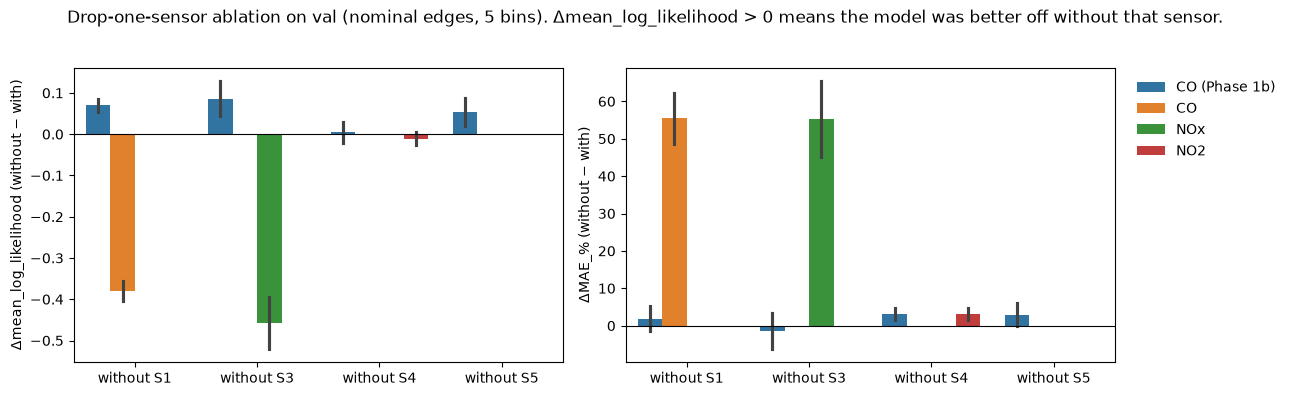

In [ ]:
plot = abl_delta.assign(
    who=np.where(abl_delta.model == "Phase 1b", "CO (Phase 1b)", abl_delta.gas)
)
hue_order = ["CO (Phase 1b)", *map(short, gases)]

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, m in zip(axes, ["Δmean_log_likelihood", "ΔMAE_%"], strict=True):
    sns.barplot(
        data=plot,
        x="evidence",
        y=m,
        hue="who",
        hue_order=hue_order,
        errorbar="sd",
        ax=ax,
        legend=ax is axes[-1],
    )
    ax.axhline(0, c="black", lw=0.8)
    ax.set_xlabel("")
    ax.set_ylabel(f"{m} (without − with)")
axes[-1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
fig.suptitle(
    f"Drop-one-sensor ablation on val (nominal edges, {chosen} bins). "
    "Δmean_log_likelihood > 0 means the model was better off without that sensor.",
    y=1.03,
)
plt.tight_layout()
plt.savefig(config.paths.figure(FIG, "ablation.png"), bbox_inches="tight")
plt.show()

**Reading:** **The Phase 1b overconfidence is reproduced, and Phase 2 removes it.**
- **Phase 1b:** removing S1, S3 or S5 *raises* CO's mean log-likelihood (+0.070 ± 0.015, +0.085 ± 0.042, +0.053 ± 0.034; S4 +0.004 ± 0.025), and its ECE is 0.161 vs 0.035 for Phase 2. The sensors are double-counted as independent CO witnesses.
- **Phase 2:** no removal raises log-likelihood. Each gas depends only on its own sensor: CO without S1 loses 0.380 ± 0.024 nats and its MAE rises 55 ± 7%; NOx without S3 loses 0.457 ± 0.062 and its MAE rises 55 ± 10%; NO2 without S4 loses only 0.011 ± 0.016 nats (MAE +3.2 ± 1.6%), so S4 says little about NO2. Removing a sensor changes the other gases by exactly 0, and removing **S5 changes nothing**, as expected for a sensor with no gas parent.
- **The trade-off:** Phase 1b's CO MAE is lower (0.475 ± 0.033 vs 0.543 ± 0.037 mg/m³, the same as Phase 1's 5-bin result). S3, S4 and S5 do carry CO information; Phase 1b uses it but overcounts it, and nominal Phase 2 ignores it. The cross edges in 3a are the principled way to use it.

### 9.2 EM vs complete-case

**Complete-case** counts each CPT only on the hours where the node and all its parents are observed. That is what `LayeredBN` starts EM from, so it is `max_iter=0`. (`max_iter=1` would already be one E-step plus one M-step past it, i.e. one round of EM.) **EM** (`max_iter=100`, the grid's fit) also uses the hours with a missing reference, weighting each possible gas level by its posterior.

First, how many training hours complete-case loses per CPT:

In [ ]:
train = splits[(chosen, config.seed)]["train"]
lost = {
    short(node): train[[*parents, node]].isna().any(axis=1).mean()
    for node, parents in structure().items()
}
pd.Series(lost, name="fraction of train hours dropped by complete-case").round(
    3
).to_frame().T

,CO,NOx,NO2,S1,S3,S4,S5
fraction of train hours dropped by complete-case,0.192,0.156,0.157,0.192,0.156,0.157,0.0


In [ ]:
rows = []
for seed in SEEDS:
    sp = splits[(chosen, seed)]
    em_fits = {
        "EM": fits[(chosen, seed)],
        "complete-case": fit_bn(sp, structure(), max_iter=0),
    }
    for label, bn in em_fits.items():
        heldout_ll = bn.log_likelihood(sp["val"]) / len(
            sp["val"]
        )  # log P(observed cells | inputs), per hour
        for gas in gases:
            if label == "EM":
                proba = posteriors[(chosen, seed, "BN")][gas]
            else:
                proba = bn.predict_proba(sp["val"], gas, evidence)
            rows.append(
                {
                    "fit": label,
                    "seed": seed,
                    "gas": short(gas),
                    "heldout_ll": heldout_ll,
                    **gas_metrics(proba, sp, gas),
                }
            )
    print(f"seed {seed} done", flush=True)

em = pd.DataFrame(rows)
em.to_csv(config.paths.result(FIG, "em_vs_complete_case.csv"), index=False)
em_cols = ["MAE", "RMSE", "mean_log_likelihood", "ECE", "heldout_ll"]
mean_std(em, ["gas", "fit"], em_cols)

seed 0 done


seed 1 done


seed 2 done


,,n,MAE,RMSE,mean_log_likelihood,ECE,heldout_ll
gas,fit,,,,,,
CO,EM,1853,0.543 ± 0.037,0.775 ± 0.049,-0.994 ± 0.044,0.035 ± 0.006,-8.632 ± 0.061
NOx,EM,1855,87.343 ± 4.703,125.626 ± 11.404,-1.046 ± 0.052,0.038 ± 0.015,-8.632 ± 0.061
NO2,EM,1855,30.809 ± 2.626,40.038 ± 4.335,-1.448 ± 0.027,0.076 ± 0.004,-8.632 ± 0.061
CO,complete-case,1853,0.54 ± 0.038,0.771 ± 0.049,-0.991 ± 0.043,0.037 ± 0.011,-8.66 ± 0.051
NOx,complete-case,1855,86.337 ± 4.426,124.733 ± 12.311,-1.038 ± 0.054,0.046 ± 0.017,-8.66 ± 0.051
NO2,complete-case,1855,30.442 ± 2.752,39.668 ± 4.451,-1.432 ± 0.034,0.068 ± 0.004,-8.66 ± 0.051


In [ ]:
# paired: EM − complete-case on the same seed (negative MAE / RMSE / ECE = EM better; positive log-lik = EM better)
em_idx = em.set_index(["fit", "seed", "gas"])
em_diff = (
    em_idx.loc["EM", em_cols] - em_idx.loc["complete-case", em_cols]
).reset_index()
mean_std(em_diff, ["gas"], em_cols, digits=4)

,MAE,RMSE,mean_log_likelihood,ECE,heldout_ll
gas,,,,,
CO,0.0037 ± 0.0024,0.0043 ± 0.0019,-0.0031 ± 0.0041,-0.0021 ± 0.0145,0.0276 ± 0.016
NOx,1.0063 ± 0.4497,0.8937 ± 1.1359,-0.0075 ± 0.0047,-0.0086 ± 0.0029,0.0276 ± 0.016
NO2,0.367 ± 0.1445,0.3704 ± 0.1306,-0.0163 ± 0.0079,0.0078 ± 0.0075,0.0276 ± 0.016


**Reading:** **EM gains almost nothing here.**
- Complete-case drops 16–19% of train hours per gas CPT and per sensor CPT (S5 loses none, since it has no gas parent).
- **Joint fit:** EM's held-out joint log-likelihood is higher by only +0.028 ± 0.016 nats/hour.
- **Per gas, EM is slightly worse than complete-case:** CO MAE +0.004 ± 0.002 mg/m³, NOx +1.0 ± 0.4 ppb, NO2 +0.37 ± 0.14 µg/m³, with log-lik −0.003 to −0.016. The differences are small next to the seed-to-seed spread.
- **Why, most likely:** with nominal edges, the only information about a missing gas comes from its own sensor and the hour, which is exactly what the CPTs being updated already encode, so EM's filled-in hours mostly reinforce the complete-case estimates. The gaps are also concentrated in a few outage periods (A3), so they add hours from particular months rather than new information. For the report: complete-case is as good as EM for this network.

## 10. Assumptions A1–A4

### A1: are the gases independent given the hour?

Two checks, on the hours where both gases are observed:
1. **Partial Spearman ρ** of each gas pair, controlling for the hour (24 dummies), on train. Near 0 would support A1.
2. **In the BN's own terms:** held-out log-likelihood gain per hour of P(gᵢ | gⱼ, hour) over P(gᵢ | hour), fit on train and scored on val, at the chosen bins. A clearly positive gain means gⱼ still tells us about gᵢ within the hour, so A1 is violated.

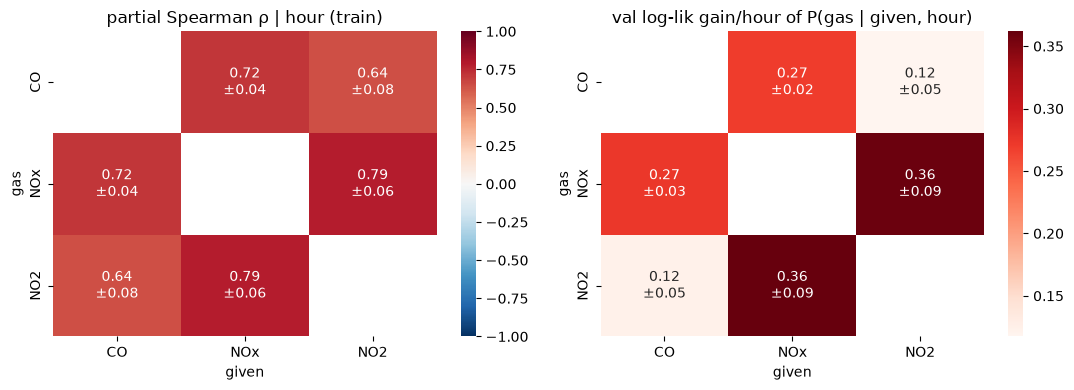

In [ ]:
rows = []
for seed in SEEDS:
    sp = splits[(chosen, seed)]
    for gi in gases:
        for gj in gases:
            if gi == gj:
                continue
            rho, _ = partial_spearman(
                sp["train_raw"], gi, gj, [Time.HOUR], categorical=[Time.HOUR]
            )
            cols = [Time.HOUR, gi, gj]
            train_ij, val_ij = sp["train"][cols].dropna(), sp["val"][cols].dropna()
            if val_ij.empty:
                continue
            base = LayeredBN(
                Network(structure={gi: (Time.HOUR,)}, cards=sp["cards"]), alpha=ALPHA
            ).fit(train_ij)
            full = LayeredBN(
                Network(structure={gi: (Time.HOUR, gj)}, cards=sp["cards"]), alpha=ALPHA
            ).fit(train_ij)
            gain = (full.log_likelihood(val_ij) - base.log_likelihood(val_ij)) / len(
                val_ij
            )
            rows.append(
                {
                    "seed": seed,
                    "gas": short(gi),
                    "given": short(gj),
                    "partial_rho": rho,
                    "ll_gain": gain,
                    "n": len(val_ij),
                }
            )

a1 = pd.DataFrame(rows)
a1.to_csv(config.paths.result(FIG, "a1_gas_given_gas.csv"), index=False)

names = [short(g) for g in gases]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (col, title, cmap, center) in zip(
    axes,
    [
        ("partial_rho", "partial Spearman ρ | hour (train)", "RdBu_r", 0),
        ("ll_gain", "val log-lik gain/hour of P(gas | given, hour)", "Reds", None),
    ],
    strict=True,
):
    m = (
        a1.groupby(["gas", "given"])[col]
        .mean()
        .unstack()
        .reindex(index=names, columns=names)
    )
    s = (
        a1.groupby(["gas", "given"])[col]
        .std()
        .unstack()
        .reindex(index=names, columns=names)
    )
    annot = (m.round(2).astype(str) + "\n±" + s.round(2).astype(str)).where(
        m.notna(), ""
    )
    sns.heatmap(
        m,
        annot=annot.values,
        fmt="",
        cmap=cmap,
        center=center,
        ax=ax,
        vmin=-1 if center == 0 else None,
        vmax=1 if center == 0 else None,
    )
    ax.set_title(title)
plt.tight_layout()
plt.savefig(config.paths.figure(FIG, "a1_gases_given_hour.png"), bbox_inches="tight")
plt.show()

**Reading:** **A1 is not supported.** Within an hour, the gases still co-move strongly:
- Partial ρ | hour is 0.64–0.79 (NO2–NOx 0.79, CO–NOx 0.72, CO–NO2 0.64), on 1750–1855 val hours per pair.
- Adding one gas as a parent of another improves held-out log-likelihood by 0.36 nats/hour (NO2 | NOx and NOx | NO2), 0.27 (CO | NOx) and 0.12 (CO | NO2).
- Traffic drives all of them hour by hour, not just through the daily cycle.

This is the main structural limitation of Phase 2: with nominal edges and A1, the network splits into three separate gas models, so no evidence about one gas reaches another. Phase 3a lets evidence cross between gases through shared sensor children (the cross edges), and 3b adds a shared latent traffic parent above the gases.

### A2: are the sensors independent given their gas parents and the weather?

Partial Spearman ρ between every pair of sensors, controlling for **all three gases**, T, RH and hour (train, chosen bins' split for seed 0, hours with every gas observed). The BN's A2 is a stronger claim (each sensor depends only on *its own* gas parent), so controlling for all gases is generous to it: anything left is dependence the BN can't represent. Large values mean the sensors share something the network doesn't model (common drift, a shared heater, an unmodelled gas such as O3), which double-counts their evidence.

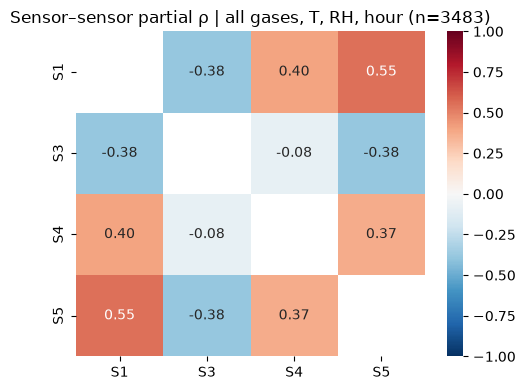

In [ ]:
train_raw = splits[(chosen, config.seed)]["train_raw"]
controls = [*gases, *weather, Time.HOUR]
a2 = pd.DataFrame(
    np.nan, index=[short(s) for s in sensors], columns=[short(s) for s in sensors]
)
for i, si in enumerate(sensors):
    for sj in sensors[i + 1 :]:
        rho, n_a2 = partial_spearman(
            train_raw, si, sj, controls, categorical=[Time.HOUR]
        )
        a2.loc[short(si), short(sj)] = a2.loc[short(sj), short(si)] = rho
a2.to_csv(config.paths.result(FIG, "a2_sensor_partial_rho.csv"))

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(a2, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title(f"Sensor–sensor partial ρ | all gases, T, RH, hour (n={n_a2})")
plt.tight_layout()
plt.savefig(config.paths.figure(FIG, "a2_sensor_residuals.png"), bbox_inches="tight")
plt.show()

**Reading:** **A2 is not supported: the sensors stay dependent after controlling for every gas.**
- The largest residual correlations are S1–S5 0.55, S1–S4 0.40, S1–S3 −0.38, S3–S5 −0.38 and S4–S5 0.37.
- S5 is the clearest case. It has no gas parent here, yet it correlates with S1 and S4 beyond what the gases explain; it responds to CO and NOx (the cross-sensitivity study), which the nominal network can't use.
- These shared signals are what the cross edges in 3a and the latent node in 3b are meant to capture.

### A3: is missingness ignorable?

MAR can't be proven from the data, but two things make it plausible or not:
- **When** the references are missing. Long contiguous gaps point to analyzer downtime (unrelated to the gas level); scattered gaps at high or low readings would not.
- **Whether the sensors look different** on hours with a missing reference. Under MCAR the nominal sensor's distribution is the same either way; a shift means missingness depends on the gas level, which is fine for MAR only if the shift is explained by the observed sensors, hour and weather.

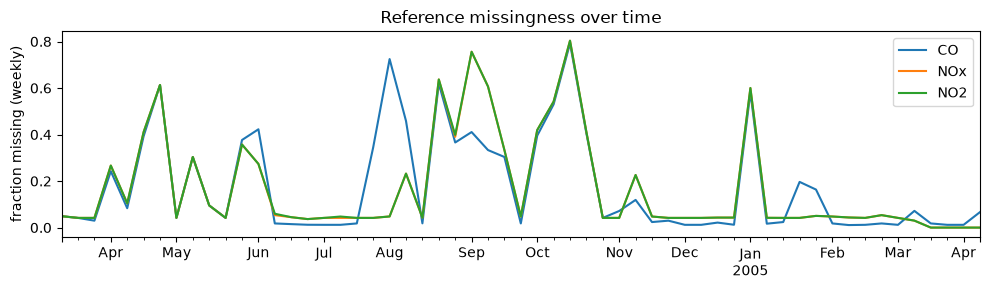

,CO via S1,NOx via S3,NO2 via S4
median when reference observed,1075.0,792.0,1460.0
median when reference missing,1015.0,869.0,1467.5
hours missing,1647.0,1595.0,1598.0


In [ ]:
missing = df[list(gases)].isna().rename(columns=short)
fig, ax = plt.subplots(figsize=(10, 3))
missing.resample("W").mean().plot(ax=ax)
ax.set_ylabel("fraction missing (weekly)")
ax.set_xlabel("")
ax.set_title("Reference missingness over time")
plt.tight_layout()
plt.savefig(
    config.paths.figure(FIG, "a3_missingness_over_time.png"), bbox_inches="tight"
)
plt.show()

# median of each gas's nominal sensor, on hours with vs without that gas's reference
pd.DataFrame(
    {
        f"{short(g)} via {short(s)}": {
            "median when reference observed": df.loc[df[g].notna(), s].median(),
            "median when reference missing": df.loc[df[g].isna(), s].median(),
            "hours missing": int(df[g].isna().sum()),
        }
        for s, (g,) in nominal.items()
    }
).round(1)

**Reading:** **MAR is plausible for all three gases.** Their gaps are a ~5% background plus multi-week outages (April–May, August–October, early January), with NOx and NO2 dropping out together (one analyzer). That looks like analyzer downtime, not the gas level. The nominal sensors read only somewhat differently during gaps (S1 median 1015 vs 1075, S3 869 vs 792, S4 unchanged at ~1460).

### A4: are hours independent?

Lag-1 autocorrelation of the concentration residuals (estimate − reference) on consecutive val hours, chosen bins. Near 0 supports A4; a large value means the next hour's error is predictable from this one's, which a temporal model would use.

In [ ]:
def lag1_autocorr(resid):
    r = resid.dropna()
    consecutive = r.index.to_series().diff() == pd.Timedelta("1h")
    return r[consecutive].corr(r.shift(1)[consecutive])


rows = []
for seed in SEEDS:
    sp = splits[(chosen, seed)]
    for gas in gases:
        estimate = sp["estimates"]["BN"][short(gas)]
        rows.append(
            {
                "seed": seed,
                "gas": short(gas),
                "lag1_autocorr": lag1_autocorr(estimate - sp["val_raw"][gas]),
            }
        )
a4 = pd.DataFrame(rows)
mean_std(a4, ["gas"], ["lag1_autocorr"])

,lag1_autocorr
gas,
CO,0.678 ± 0.035
NOx,0.76 ± 0.039
NO2,0.88 ± 0.01


**Reading:** **A4 is not supported.** The lag-1 autocorrelation of the concentration residuals is 0.68 ± 0.04 (CO), 0.76 ± 0.04 (NOx) and 0.88 ± 0.01 (NO2):
- When the model is off in one hour, it's off the same way the next hour, so neighbouring hours carry information the static network ignores. Temporal modelling is future work.
- It also means the effective number of independent hours is much smaller than `n`. Seed-to-seed std is the better guide to uncertainty.

## 11. Drift check: time-based split

The blocked split mixes weeks from the whole year into train and val. A chronological split (train = first half of the data, val = the next quarter) asks whether CPTs learned on earlier months still hold later. The sensors are known to drift, so some loss is expected. Chosen bins; one run, since the split has no seed. Compare with the blocked-split val numbers.

In [ ]:
ts = make_split(config.seed, chosen, split=time_split)
print(
    {
        k: f"{ts[k].index.min():%Y-%m-%d} → {ts[k].index.max():%Y-%m-%d}"
        for k in ("train_raw", "val_raw", "test_raw")
    }
)
bn_ts = fit_bn(ts, structure())
hour_ts = fit_hour(ts)

scorable = [
    g for g in gases if ts["val"][g].notna().any()
]  # a gas with no val readings can't be scored
print("scored on the time split:", [short(g) for g in scorable])
rows = []
for model in (bn_ts, hour_ts):
    rows += evaluate_all(model, ts, gases=scorable)[1]
drift = pd.DataFrame(rows).assign(split="time")

cols = ["n", "MAE", "RMSE", "floor_MAE", "mean_log_likelihood", "ECE"]
blocked = (
    grid[grid.bins == chosen]
    .groupby(["gas", "model"], sort=False)[cols]
    .mean()
    .reset_index()
    .assign(split="blocked (mean over seeds)")
)
drift_table = (
    pd.concat([blocked, drift[blocked.columns]])
    .set_index(["gas", "model", "split"])
    .sort_index()
)
drift_table.to_csv(config.paths.result(FIG, "drift_time_split.csv"))
drift_table.round(3)

{'train_raw': '2004-03-10 → 2004-09-20', 'val_raw': '2004-09-20 → 2004-12-26', 'test_raw': '2004-12-26 → 2005-04-04'}


scored on the time split: ['CO', 'NOx', 'NO2']


n      MAE     RMSE  \
gas model            split                                                   
CO  BN               blocked (mean over seeds)  1853.000    0.543    0.775   
                     time                       1832.000    0.810    1.281   
    HourOnlyBaseline blocked (mean over seeds)  1853.000    0.845    1.142   
                     time                       1832.000    1.149    1.658   
NO2 BN               blocked (mean over seeds)  1854.667   30.809   40.038   
                     time                       1783.000   36.753   48.206   
    HourOnlyBaseline blocked (mean over seeds)  1854.667   31.838   41.279   
                     time                       1783.000   33.281   44.383   
NOx BN               blocked (mean over seeds)  1855.000   87.343  125.626   
                     time                       1783.000  214.381  293.508   
    HourOnlyBaseline blocked (mean over seeds)  1855.000  135.970  185.692   
                     time                       1783.000  254.880  337.330   

                                                floor_MAE  \
gas model            split                                  
CO  BN               blocked (mean over seeds)      0.320   
                     time                           0.518   
    HourOnlyBaseline blocked (mean over seeds)      0.320   
                     time                           0.518   
NO2 BN               blocked (mean over seeds)     11.349   
                     time                          13.402   
    HourOnlyBaseline blocked (mean over seeds)     11.349   
                     time                          13.402   
NOx BN               blocked (mean over seeds)     50.439   
                     time                         159.181   
    HourOnlyBaseline blocked (mean over seeds)     50.439   
                     time                         159.181   

                                                mean_log_likelihood    ECE  
gas model            split                                                  
CO  BN               blocked (mean over seeds)               -0.994  0.035  
                     time                                    -1.112  0.113  
    HourOnlyBaseline blocked (mean over seeds)               -1.373  0.038  
                     time                                    -1.454  0.118  
NO2 BN               blocked (mean over seeds)               -1.448  0.076  
                     time                                    -1.897  0.210  
    HourOnlyBaseline blocked (mean over seeds)               -1.457  0.045  
                     time                                    -1.457  0.035  
NOx BN               blocked (mean over seeds)               -1.046  0.038  
                     time                                    -1.380  0.108  
    HourOnlyBaseline blocked (mean over seeds)               -1.500  0.045  
                     time                                    -1.930  0.198

**Reading:** **Clear drift.** Trained on March–September 2004 and scored on September–December 2004 (5 bins).
- **CO:** MAE 0.543 → 0.810 mg/m³, ECE 0.035 → 0.113. Still well ahead of the baseline (1.149).
- **NOx:** MAE more than doubles (87.3 → 214.4 ppb) and the floor triples (50 → 159), because winter NOx is far above anything in the summer training bins, and the estimate can't exceed the top bin's summer mean. Still ahead of the baseline (254.9).
- **NO2:** the BN falls *below* the hour baseline (MAE 36.8 vs 33.3 µg/m³, log-lik −1.90 vs −1.46, ECE 0.21).
- The hour baseline degrades too, so part of this is a seasonal shift in gas levels rather than only sensor drift. The blocked-split numbers are optimistic for later months.

## 12. Test set: chosen configuration, reported once

Everything above was chosen on val. This is the only cell that reads **test**. Same fitted models as the grid (trained on train only), same metrics.

In [ ]:
rows = []
for seed in SEEDS:
    sp = splits[(chosen, seed)]
    for model in (fits[(chosen, seed)], fit_hour(sp)):
        rows += [{"seed": seed, **r} for r in evaluate_all(model, sp, part="test")[1]]
test_results = pd.DataFrame(rows)
test_results.to_csv(config.paths.result(FIG, "test_chosen.csv"), index=False)
mean_std(
    test_results,
    ["gas", "model"],
    ["MAE", "floor_MAE", "RMSE", "mean_log_likelihood", "ECE"],
)

,,n,MAE,floor_MAE,RMSE,mean_log_likelihood,ECE
gas,model,,,,,,
CO,BN,1751,0.597 ± 0.048,0.369 ± 0.02,0.926 ± 0.075,-0.984 ± 0.033,0.03 ± 0.006
NOx,BN,1776,97.487 ± 15.977,54.981 ± 3.392,147.757 ± 23.891,-1.051 ± 0.058,0.041 ± 0.015
NO2,BN,1775,30.261 ± 1.236,11.036 ± 0.33,39.527 ± 1.198,-1.392 ± 0.036,0.064 ± 0.009
CO,HourOnlyBaseline,1751,0.935 ± 0.032,0.369 ± 0.02,1.331 ± 0.061,-1.378 ± 0.01,0.031 ± 0.006
NOx,HourOnlyBaseline,1776,143.878 ± 18.581,54.981 ± 3.392,206.938 ± 26.629,-1.481 ± 0.022,0.016 ± 0.007
NO2,HourOnlyBaseline,1775,30.965 ± 1.78,11.036 ± 0.33,40.689 ± 1.575,-1.423 ± 0.025,0.026 ± 0.006


## Summary

Numbers are val, mean ± std over seeds 0–2, at the chosen 5 bins unless marked otherwise. Network: nominal edges only (S1 ← CO, S3 ← NOx, S4 ← NO2; S5 no gas parent), T + RH.

- **Per gas vs baseline (concentration MAE):**
  - CO: 0.543 ± 0.037 vs 0.845 mg/m³ (floor 0.320, n = 1853).
  - NOx: 87.3 ± 4.7 vs 136.0 ppb (floor 50.4, n = 1855).
  - NO2: 30.8 ± 2.6 vs 31.8 µg/m³ (floor 11.3, n = 1855), within noise of the baseline; at 3 bins it is slightly worse than the baseline. S4 carries little NO2 information.

- **Chosen configuration:** 
  - 5 bins. Relative MAE over the three gases is 0.751 ± 0.006 vs 0.808 ± 0.017 at 3 bins.

- **CO vs Phase 1:** 
  - CO MAE is worse than Phase 1's (0.598 vs 0.544 at 3 bins, 0.543 vs 0.475 at 5 bins), because with nominal edges CO only sees S1, but it is far better calibrated (ECE 0.035 vs 0.161 at 5 bins) and has better log-likelihood at 3 bins (−0.606 vs −0.661).

- **Drop-one-sensor ablation:** 
  - Phase 1b reproduces the overconfidence (removing S1, S3 or S5 raises CO's log-lik by +0.05 to +0.09; ECE 0.161). Phase 2 removes it: no removal raises log-lik, each gas leans only on its own sensor, and S5 has no effect. Phase 1b's CO MAE is lower (0.475 vs 0.543), so the other sensors do carry CO information that nominal edges leave unused.

- **EM vs complete-case:** 
  - EM improves the held-out joint log-lik by only +0.028 ± 0.016 and is slightly worse per gas (CO MAE +0.004, NOx +1.0 ppb, NO2 +0.37 µg/m³).

- **Calibration:** 
  - CO and NOx are well calibrated (ECE 0.035, 0.038, better than the baseline). NO2 is overconfident (0.076 vs 0.045).

- **Test** (5 bins, reported once):
  - CO: MAE 0.597 ± 0.048 vs 0.935 mg/m³, log-lik −0.984 vs −1.378 (n = 1751).
  - NOx: MAE 97.5 ± 16.0 vs 143.9 ppb (n = 1776).
  - NO2: MAE 30.3 ± 1.2 vs 31.0 µg/m³ (n = 1775).

- **Drift:** 
  - On a chronological split, all three degrade. CO MAE 0.543 → 0.810, NOx 87 → 214 ppb (winter levels exceed the training bins), and NO2 falls below the hour baseline.

- **Assumptions:**
  - **A1 not supported:** gases co-move within the hour (partial ρ 0.64–0.79, log-lik gains up to 0.36 nats/hour).
  - **A2 not supported:** sensor residuals stay correlated up to 0.55 given all gases, S5 with S1 most of all.
  - **A3 plausible:** gaps look like analyzer outages.
  - **A4 not supported:** lag-1 residual autocorrelation is 0.68–0.88.

- **Limitations and what comes next:**
  - With nominal edges and A1, the network is three separate gas models: no evidence crosses between gases, and S5 is unused. Phase 3a adds the cross-sensitivity edges to use that information; the 2 → 3a difference measures what they buy.
  - A1 and A2 point to a shared traffic signal, which is what Phase 3b's latent node models. A4 points to temporal modelling, which is future work.
  - NO2 is barely predictable from its nominal sensor, and all gases drift across seasons.

## 13. Concentration Evaluation

For each gas, we have:
1. Time-series plot: reference (black) vs. our posterior-mean estimate (green), with the bin ranges shaded and dotted lines at the training bin means.
2. MAE bar chart: resolution floor, the phase's BN, and the hour-only baseline, with values on the bars 
3. Table: MAE/RMSE (mean ± std across seeds) plus skill_vs_baseline and gap_closed

The trace plots show seed 0 on one validation week. The MAE bars and the table are means over the three split seeds.

This section is made so that we can easily compare phases.

In [ ]:
from cse250a.modules.eval.concentration_eval import WEEK, concentration_section

PHASE_LABEL, N_BINS = "Phase 2", 3
SECTION_SEED = SEEDS[0]
rep = splits[(N_BINS, SECTION_SEED)]

print("hours in week:", len(rep["val_raw"].loc[WEEK]))  # about 168

edges = {g: np.asarray(rep["discretizer"].edges[g]) for g in gases}
for g in gases:
    print(g, edges[g])

hours in week: 168
CO(GT) [1.2 2.3]
NOx(GT) [100. 223.]
NO2(GT) [ 83. 123.]


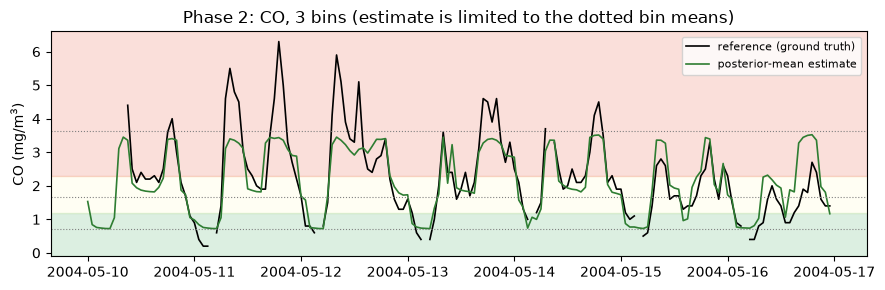

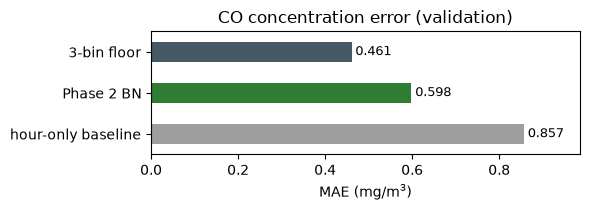

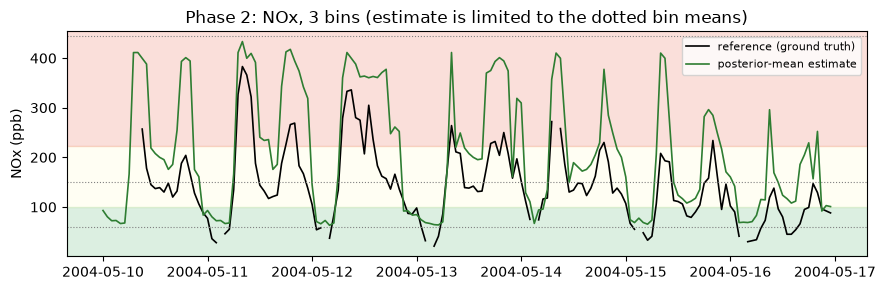

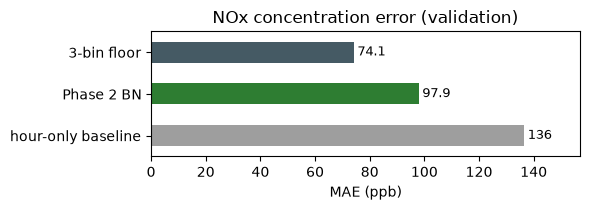

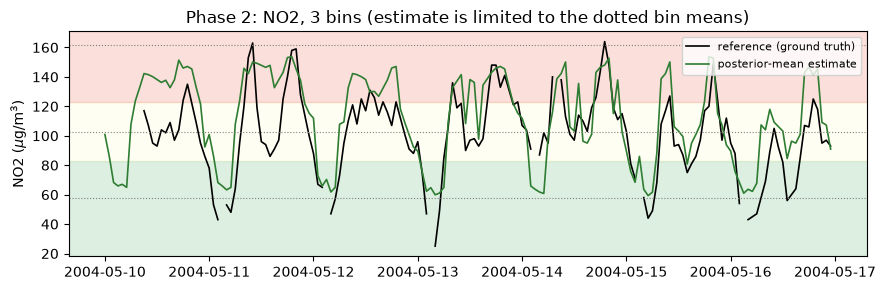

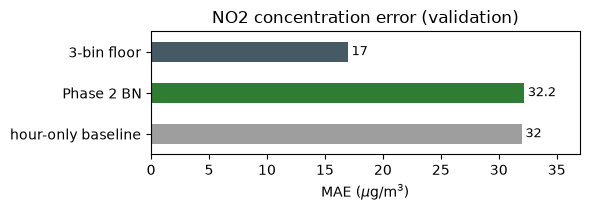

,bins,BN MAE,hour MAE,floor MAE,BN RMSE,hour RMSE,skill_vs_baseline,gap_closed
gas,,,,,,,,
CO(GT),3,0.598 ± 0.033,0.857 ± 0.039,0.461 ± 0.058,0.868 ± 0.051,1.151 ± 0.036,0.301 ± 0.042,0.658 ± 0.042
NO2(GT),3,32.182 ± 2.615,31.977 ± 2.802,16.981 ± 1.757,41.458 ± 4.261,41.443 ± 3.989,-0.007 ± 0.020,-0.018 ± 0.046
NOx(GT),3,97.872 ± 3.967,136.469 ± 5.586,74.131 ± 18.198,140.423 ± 10.534,186.456 ± 19.586,0.282 ± 0.044,0.671 ± 0.277


In [ ]:
grid_s = concentration_grid[concentration_grid["bins"] == N_BINS][
    ["bins", "seed", "gas", "model", "MAE", "RMSE"]
]

summary_table = concentration_section(
    gases=gases, grid=grid_s,
    est_val={g: rep["estimates"]["BN"][short(g)] for g in gases},
    val_raw=rep["val_raw"], c_bar=rep["c_bar"], edges=edges,
    week=WEEK, phase_label=PHASE_LABEL, n_bins=N_BINS,
    fig_path=lambda f: config.paths.figure(FIG, f),
)
summary_table

### Summary Report

#### Interpretations
- Phase 2's BN removes about 30% of the hour only baseline's MAE for CO (0.301 ± 0.042) and about 28% for NOx (0.282 ± 0.044). For NO2, the BN performs about 1% worse than than the basline (-0.007 ± 0.020). 
- The BN closes about 66% of the gap between the baseline and the resolution floor for CO (0.658 ± 0.042), and about 67% for NOx (0.671 ± 0.277), so there is little room for improvement in the model for these gases with 3 bins. 
- For No2, the gap between the baseline and the resolution floor widens about 2% (-0.018 ± 0.046), so this BN performs slightly worse than the baseline with this bin count. 


#### Limitations
- Only 3 bins are used, which means the resolution is low, and using more bins would help with that, but it would make it so we have less evidence per bin, so we kept the 3 bins
- The concentration estimate uses year-round training bin means, so in low-pollution seasons a “high” posterior overshoots. More bins narrow the top bin; season-aware bin means would address the seasonal part and are future work.
- The trace plots show seed 0 on one validation week. The MAE bars and the table are means over the three split seeds.

*AI use: code started and debugged with help from Claude, edited, reviewed and run by me.*